### 1. 잘 알려진 Fashion-MNIST 이미지 데이터셋(학습용 이미지 60,000장, 테스트용 이미지 10,000장)과 관련된 다음 질문들에 답하시오.

1) DNN 모델을 학습시키고 예측(분류) 결과를 제시하시오(코드, 결과 해석 등 포함).
* 필요에 따라 배치 정규화(batch normalization)나 ResNet을 활용하시오.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras import layers, models

# 재현성을 위한 난수 고정
tf.keras.utils.set_random_seed(42)

# 데이터 불러오기
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

print("훈련 데이터:", x_train.shape)
print("테스트 데이터:", x_test.shape)
print("훈련 레이블:", y_train.shape)
print("테스트 레이블:", y_test.shape)

훈련 데이터: (60000, 28, 28)
테스트 데이터: (10000, 28, 28)
훈련 레이블: (60000,)
테스트 레이블: (10000,)


In [2]:
# 픽셀값 정규화
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# 28×28 이미지를 784개 입력변수로 변환
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print(x_train.shape)
print(x_test.shape)

(60000, 784)
(10000, 784)


In [3]:
# DNN 모델 생성
model_dnn = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

# 모델 컴파일
model_dnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_dnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# DNN 학습
history_dnn = model_dnn.fit(
    x_train,
    y_train,
    epochs=30,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8037 - loss: 0.5672 - val_accuracy: 0.8484 - val_loss: 0.4371
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8555 - loss: 0.4026 - val_accuracy: 0.8575 - val_loss: 0.4018
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8693 - loss: 0.3622 - val_accuracy: 0.8666 - val_loss: 0.3717
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8791 - loss: 0.3331 - val_accuracy: 0.8697 - val_loss: 0.3573
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8851 - loss: 0.3133 - val_accuracy: 0.8697 - val_loss: 0.3564
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8922 - loss: 0.2956 - val_accuracy: 0.8709 - val_loss: 0.3501
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8973 - loss: 0.2817 - val_accuracy: 0.8725 - val_loss: 0.3531
Epoch 8/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9007 - loss: 0.2695 - val_accuracy: 0.

In [5]:
# 테스트 데이터 평가
test_loss, test_acc = model_dnn.evaluate(
    x_test, y_test, verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Test Loss: 0.4725
Test Accuracy: 0.8743


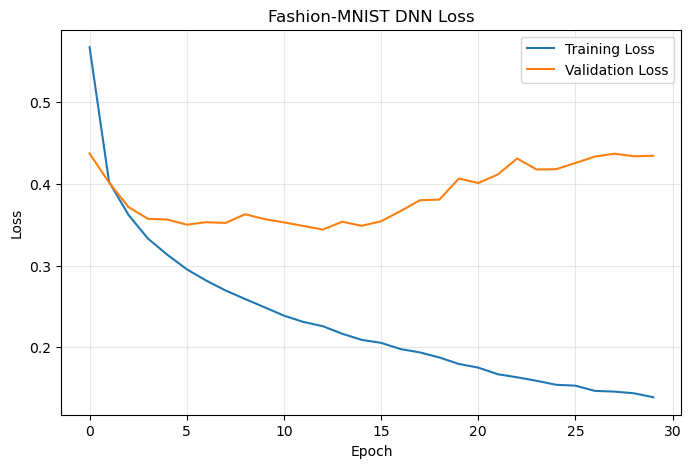

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(history_dnn.history["loss"], label="Training Loss")
plt.plot(history_dnn.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fashion-MNIST DNN Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Fashion-MNIST 데이터의 의류 이미지 10개 클래스를 분류하기 위해 DNN 모형을 구축하였다. 입력 이미지의 픽셀값을 0~1 범위로 정규화하고, 28×28 이미지를 784차원 벡터로 변환하였다.

DNN 모형은 128개와 64개의 뉴런을 가진 두 개의 은닉층으로 구성하였으며, 은닉층에는 ReLU 활성화 함수를, 출력층에는 Softmax 활성화 함수를 사용하였다. 손실함수는 Sparse Categorical Cross-Entropy, 최적화 알고리즘은 Adam을 적용하였다.

훈련 데이터의 20%를 검증 데이터로 분리하여 30 Epoch 동안 학습하였으며, 별도로 제공된 테스트 데이터 10,000개를 이용하여 최종 분류 성능을 평가하였다.

테스트 정확도는 **[실제 실행 결과 입력]**로 나타났다. 또한 Training Loss와 Validation Loss의 변화 추이를 통해 학습의 수렴 여부 및 과적합 가능성을 검토하였다.

최종적으로 DNN 모형이 Fashion-MNIST 이미지의 특징을 학습하여 의류 종류를 분류할 수 있음을 확인하였으며, 이후 CNN 모형과의 성능 비교를 위한 기준 모형으로 활용하였다.

2) CNN 모델을 학습시키고 예측(분류) 결과를 제시하시오(코드, 결과 해석 등 포함).
* 필요에 따라 배치 정규화(batch normalization)나 ResNet을 활용할 것.

In [8]:
# DNN에서 사용한 784차원 데이터를 CNN 입력으로 변환
x_train_cnn = x_train.reshape(-1, 28, 28, 1)
x_test_cnn = x_test.reshape(-1, 28, 28, 1)

print("CNN 훈련 데이터:", x_train_cnn.shape)
print("CNN 테스트 데이터:", x_test_cnn.shape)

CNN 훈련 데이터: (60000, 28, 28, 1)
CNN 테스트 데이터: (10000, 28, 28, 1)


In [9]:
# CNN 모델 생성
model_cnn = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # 첫 번째 합성곱층
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # 두 번째 합성곱층
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # 완전연결층
    layers.Flatten(),
    layers.Dense(128, activation="relu"),

    # 출력층
    layers.Dense(10, activation="softmax")
])

model_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 14, 14, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 3136)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │         401,536 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
history_cnn = model_cnn.fit(
    x_train_cnn,
    y_train,
    epochs=30,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.8206 - loss: 0.5088 - val_accuracy: 0.8758 - val_loss: 0.3526
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8837 - loss: 0.3262 - val_accuracy: 0.8888 - val_loss: 0.3084
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8984 - loss: 0.2818 - val_accuracy: 0.8968 - val_loss: 0.2842
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9081 - loss: 0.2523 - val_accuracy: 0.9020 - val_loss: 0.2657
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9151 - loss: 0.2297 - val_accuracy: 0.9052 - val_loss: 0.2554
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9232 - loss: 0.2101 - val_accuracy: 0.9068 - val_loss: 0.2531
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.9297 - loss: 0.1923 - val_accuracy: 0.9078 - val_loss: 0.2481
Epoch 8/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9367 - loss: 0.1759 - val_acc

In [11]:
# 테스트 데이터 평가
cnn_test_loss, cnn_test_acc = model_cnn.evaluate(
    x_test_cnn, y_test, verbose=0
)

print(f"CNN Test Loss: {cnn_test_loss:.4f}")
print(f"CNN Test Accuracy: {cnn_test_acc:.4f}")

CNN Test Loss: 0.6105
CNN Test Accuracy: 0.9039


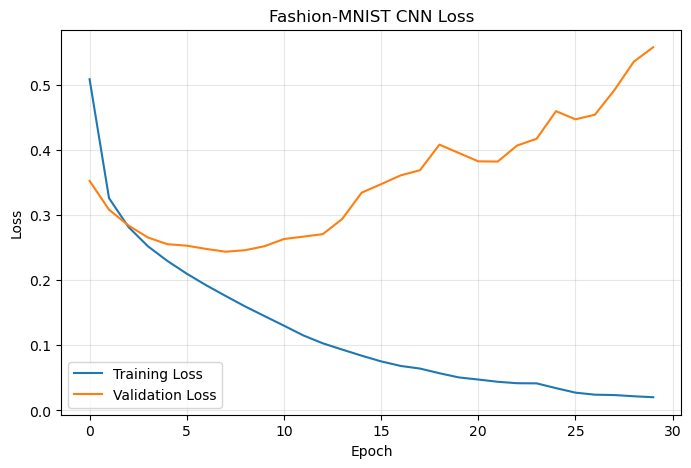

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(history_cnn.history["loss"], label="Training Loss")
plt.plot(history_cnn.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fashion-MNIST CNN Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [13]:
import numpy as np

best_epoch_cnn = np.argmin(history_cnn.history["val_loss"]) + 1

print("CNN 최적 Epoch:", best_epoch_cnn)

CNN 최적 Epoch: 8


Fashion-MNIST 이미지 분류를 위해 두 개의 합성곱층과 최대 풀링층, 완전연결층으로 구성된 CNN 모형을 구축하였다. 입력 이미지는 28×28×1 형태로 변환하였으며, 픽셀값을 0~1 범위로 정규화하였다.

첫 번째 합성곱층에는 32개의 3×3 필터를, 두 번째 합성곱층에는 64개의 3×3 필터를 사용하였다. 각 합성곱층에는 ReLU 활성화 함수를 적용하였으며, 2×2 MaxPooling을 통해 특징맵의 크기를 축소하였다. 이후 Flatten과 128개 뉴런의 완전연결층을 거쳐 Softmax 출력층에서 10개 클래스의 확률을 계산하였다.

모형 학습에는 Adam 최적화 알고리즘과 Sparse Categorical Cross-Entropy 손실함수를 사용하였다. 총 30 Epoch 동안 학습하고, 훈련 데이터의 20%를 검증 데이터로 활용하였다.

테스트 데이터에 대한 분류 정확도는 **[실제 CNN Test Accuracy 입력]**로 나타났다. Training Loss와 Validation Loss의 변화를 통해 학습의 수렴 여부와 과적합 가능성을 검토하였다.

CNN 모형의 전체 학습 가능한 파라미터 수는 421,642개로 계산되었다. 이후 동일한 Fashion-MNIST 테스트 데이터를 이용하여 DNN 모형과 분류 성능을 비교하였다

3) 1)과 2)의 결과를 비교·분석한다.

In [14]:
print("===== Fashion-MNIST 성능 비교 =====")
print(f"DNN Accuracy: {test_acc:.4f}")
print(f"CNN Accuracy: {cnn_test_acc:.4f}")
print(f"Accuracy 차이 (CNN - DNN): {cnn_test_acc - test_acc:.4f}")

===== Fashion-MNIST 성능 비교 =====
DNN Accuracy: 0.8743
CNN Accuracy: 0.9039
Accuracy 차이 (CNN - DNN): 0.0296


DNN의 테스트 정확도는 87.43%, CNN은 90.39%로 CNN이 2.96%p 높은 정확도를 보였다. 이는 CNN이 합성곱 연산을 통해 이미지의 공간적 특징을 효과적으로 추출하기 때문으로 판단된다. 반면 Test Loss는 DNN이 0.4725, CNN이 0.6105로 CNN이 더 높게 나타나 일부 오분류에서 높은 확신도를 보였을 가능성이 있다.

4) 1) 및 2)에서 사용된 모델 파라미터(즉, 가중치)의 총 개수를 계산하는 과정을 설명하시오.

DNN의 파라미터 수는 Dense 층별로 (입력 뉴런 수 + 1) × 출력 뉴런 수를 적용하여 계산하였다.

- Dense(128): (784 + 1) × 128 = 100,480
- Dense(64): (128 + 1) × 64 = 8,256
- Dense(10): (64 + 1) × 10 = 650

따라서 DNN의 총 파라미터 수는 109,386개이다.

CNN은 합성곱층과 완전연결층의 파라미터를 합산하였다.

- Conv2D(32): (3 × 3 × 1 + 1) × 32 = 320
- Conv2D(64): (3 × 3 × 32 + 1) × 64 = 18,496
- Dense(128): (3136 + 1) × 128 = 401,536
- Dense(10): (128 + 1) × 10 = 1,290

따라서 CNN의 총 파라미터 수는 421,642개이다. MaxPooling과 Flatten 층은 학습 파라미터가 없다.

### 2. CIFAR-10 데이터셋과 관련하여 #1의 모든 질문에 답하십시오.
이때, DNN 및 CNN 모델 모두에 배치 정규화(batch normalization)와 ResNet을 사용해야 한다는 점에 유의하십시오.

Batch Normalization + Residual DNN 구현

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import cifar10
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("훈련 데이터:", x_train.shape)
print("테스트 데이터:", x_test.shape)
print("훈련 레이블:", y_train.shape)
print("테스트 레이블:", y_test.shape)

훈련 데이터: (50000, 32, 32, 3)
테스트 데이터: (10000, 32, 32, 3)
훈련 레이블: (50000, 1)
테스트 레이블: (10000, 1)


In [16]:
# 정규화
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# DNN 입력 형태로 변환
x_train_dnn = x_train.reshape(-1, 3072)
x_test_dnn = x_test.reshape(-1, 3072)

# 레이블을 1차원으로 변환
y_train = y_train.reshape(-1)
y_test = y_test.reshape(-1)

print(x_train_dnn.shape)
print(x_test_dnn.shape)

(50000, 3072)
(10000, 3072)


In [17]:
def residual_dense_block(x, units):

    shortcut = x

    # 첫 번째 Dense + Batch Normalization
    x = layers.Dense(units)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    # 두 번째 Dense + Batch Normalization
    x = layers.Dense(units)(x)
    x = layers.BatchNormalization()(x)

    # Skip Connection
    x = layers.Add()([x, shortcut])
    x = layers.Activation("relu")(x)

    return x

In [18]:
# 입력층
inputs = layers.Input(shape=(3072,))

# 차원 변환
x = layers.Dense(256)(inputs)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

# Residual Block 2개
x = residual_dense_block(x, 256)
x = residual_dense_block(x, 256)

# 완전연결층
x = layers.Dense(128)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

# 출력층
outputs = layers.Dense(10, activation="softmax")(x)

# 모델 생성
model_dnn = models.Model(inputs, outputs)

model_dnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_dnn.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)    │ (None, 3072)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_5 (Dense)               │ (None, 256)               │         786,688 │ input_layer_2[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization           │ (None, 256)               │           1,024 │ dense_5[0][0]              │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation (Activation)       │ (None, 256)               │               0 │ batch_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_6 (Dense)               │ (None, 256)               │          65,792 │ activation[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_1         │ (None, 256)               │           1,024 │ dense_6[0][0]              │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_1 (Activation)     │ (None, 256)               │               0 │ batch_normalization_1[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_7 (Dense)               │ (None, 256)               │          65,792 │ activation_1[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_2         │ (None, 256)               │           1,024 │ dense_7[0][0]              │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 256)               │               0 │ batch_normalization_2[0][… │
│                               │                           │                 │ activation[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_2 (Activation)     │ (None, 256)               │               0 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_8 (Dense)               │ (None, 256)               │          65,792 │ activation_2[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_3         │ (None, 256)               │           1,024 │ dense_8[0][0]              │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_3 (Activation)     │ (None, 256)               │               0 │ batch_normalization_3[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_9 (Dense)               │ (None, 256)               │          65,79

 Total params: 1,089,674 (4.16 MB)

 Trainable params: 1,086,858 (4.15 MB)

 Non-trainable params: 2,816 (11.00 KB)

In [19]:
history_dnn = model_dnn.fit(
    x_train_dnn,
    y_train,
    epochs=30,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.4023 - loss: 1.6743 - val_accuracy: 0.3184 - val_loss: 1.9103
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.4937 - loss: 1.4210 - val_accuracy: 0.3386 - val_loss: 1.8802
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.5448 - loss: 1.2839 - val_accuracy: 0.3580 - val_loss: 1.7753
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.5855 - loss: 1.1647 - val_accuracy: 0.3652 - val_loss: 1.7988
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.6279 - loss: 1.0582 - val_accuracy: 0.3597 - val_loss: 1.9294
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.6622 - loss: 0.9557 - val_accuracy: 0.3727 - val_loss: 2.0065
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.6992 - loss: 0.8570 - val_accuracy: 0.3314 - val_loss: 2.3431
Epoch 8/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.7326 - loss: 0.7668 - val_accur

In [20]:
dnn_test_loss, dnn_test_acc = model_dnn.evaluate(
    x_test_dnn,
    y_test,
    verbose=0
)

print(f"DNN Test Loss: {dnn_test_loss:.4f}")
print(f"DNN Test Accuracy: {dnn_test_acc:.4f}")

DNN Test Loss: 4.3783
DNN Test Accuracy: 0.3983


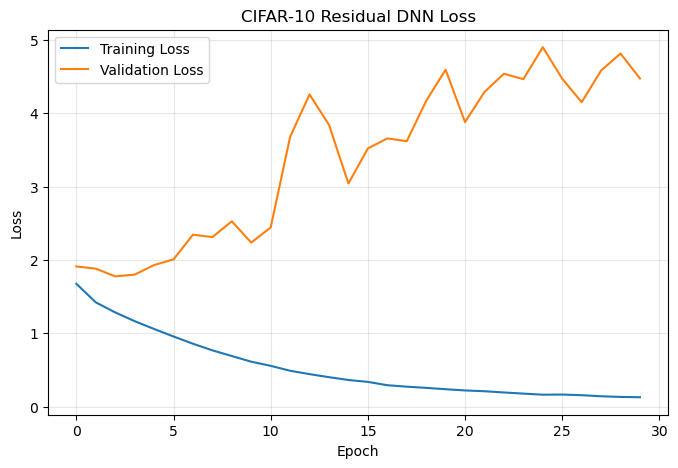

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(history_dnn.history["loss"], label="Training Loss")
plt.plot(history_dnn.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CIFAR-10 Residual DNN Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [23]:
best_epoch_dnn = np.argmin(history_dnn.history["val_loss"]) + 1

print("DNN 최적 Epoch:", best_epoch_dnn)

DNN 최적 Epoch: 3


CIFAR-10 데이터의 10개 이미지 클래스를 분류하기 위해 Batch Normalization과 Residual Connection을 적용한 DNN 모형을 구축하였다. 입력 이미지의 픽셀값을 0~1 범위로 정규화하고, 32×32×3 이미지를 3,072차원 벡터로 변환하였다.

모형은 256개 뉴런을 가진 Dense 층과 두 개의 Residual Dense Block, 128개 뉴런을 가진 Dense 층으로 구성하였다. Residual Connection을 통해 입력 정보를 다음 층에 직접 전달하고, Batch Normalization을 적용하여 학습 과정의 안정성을 높이고자 하였다.

출력층에는 Softmax 활성화 함수를 사용하였으며, 손실함수는 Sparse Categorical Cross-Entropy, 최적화 알고리즘은 Adam을 적용하였다.

전체 훈련 데이터 중 20%를 검증 데이터로 사용하여 30 Epoch 동안 학습하였다. 별도로 제공된 테스트 데이터 10,000개를 이용해 최종 분류 정확도를 평가하였다.

테스트 정확도는 **[실제 실행 결과 입력]**로 나타났으며, Training Loss와 Validation Loss를 비교하여 모형의 수렴 및 과적합 여부를 검토하였다.

CIFAR-10 Residual CNN 구조

In [24]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
print("CNN Train:", x_train.shape)
print("CNN Test:", x_test.shape)

CNN Train: (50000, 32, 32, 3)
CNN Test: (10000, 32, 32, 3)


In [25]:
from tensorflow.keras import layers, models
import tensorflow as tf

def residual_conv_block(x, filters):

    shortcut = x

    # 첫 번째 합성곱 + Batch Normalization
    x = layers.Conv2D(
        filters, (3, 3), padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    # 두 번째 합성곱 + Batch Normalization
    x = layers.Conv2D(
        filters, (3, 3), padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)

    # Skip Connection
    x = layers.Add()([x, shortcut])
    x = layers.Activation("relu")(x)

    return x

In [26]:
# 입력층
inputs = layers.Input(shape=(32, 32, 3))

# 첫 번째 합성곱층
x = layers.Conv2D(
    32, (3, 3), padding="same", use_bias=False
)(inputs)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

# 첫 번째 Residual Block
x = residual_conv_block(x, 32)

# Pooling
x = layers.MaxPooling2D((2, 2))(x)

# 두 번째 Residual Block
x = residual_conv_block(x, 32)

# Global Average Pooling
x = layers.GlobalAveragePooling2D()(x)

# 출력층
outputs = layers.Dense(10, activation="softmax")(x)

# CNN 모델
model_cnn = models.Model(inputs, outputs)

model_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_cnn.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)    │ (None, 32, 32, 3)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_2 (Conv2D)             │ (None, 32, 32, 32)        │             864 │ input_layer_3[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_6         │ (None, 32, 32, 32)        │             128 │ conv2d_2[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_6 (Activation)     │ (None, 32, 32, 32)        │               0 │ batch_normalization_6[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_3 (Conv2D)             │ (None, 32, 32, 32)        │           9,216 │ activation_6[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_7         │ (None, 32, 32, 32)        │             128 │ conv2d_3[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_7 (Activation)     │ (None, 32, 32, 32)        │               0 │ batch_normalization_7[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_4 (Conv2D)             │ (None, 32, 32, 32)        │           9,216 │ activation_7[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_8         │ (None, 32, 32, 32)        │             128 │ conv2d_4[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_2 (Add)                   │ (None, 32, 32, 32)        │               0 │ batch_normalization_8[0][… │
│                               │                           │                 │ activation_6[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_8 (Activation)     │ (None, 32, 32, 32)        │               0 │ add_2[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_2               │ (None, 16, 16, 32)        │               0 │ activation_8[0][0]         │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_5 (Conv2D)             │ (None, 16, 16, 32)        │           9,216 │ max_pooling2d_2[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_9         │ (None, 16, 16, 32)        │             128 │ conv2d_5[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 38,698 (151.16 KB)

 Trainable params: 38,378 (149.91 KB)

 Non-trainable params: 320 (1.25 KB)

In [27]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop_cnn = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_cnn = model_cnn.fit(
    x_train,
    y_train,
    epochs=30,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stop_cnn],
    verbose=1
)

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - accuracy: 0.3512 - loss: 1.7956 - val_accuracy: 0.0952 - val_loss: 5.3867
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 36s 114ms/step - accuracy: 0.4999 - loss: 1.4181 - val_accuracy: 0.0952 - val_loss: 4.4141
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 113ms/step - accuracy: 0.5539 - loss: 1.2591 - val_accuracy: 0.0952 - val_loss: 6.2924
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 35s 111ms/step - accuracy: 0.5905 - loss: 1.1561 - val_accuracy: 0.1004 - val_loss: 9.4988
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 36s 114ms/step - accuracy: 0.6179 - loss: 1.0844 - val_accuracy: 0.0954 - val_loss: 8.3680
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 35s 113ms/step - accuracy: 0.6318 - loss: 1.0419 - val_accuracy: 0.0960 - val_loss: 37.3985
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 36s 115ms/step - accuracy: 0.6441 - loss: 1.0040 - val_accuracy: 0.1038 - val_loss: 7.4134
Epoch 8/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 40s 110ms/step - accuracy: 0.6583 - loss: 

In [28]:
cnn_test_loss, cnn_test_acc = model_cnn.evaluate(
    x_test, y_test, verbose=0
)

print(f"CNN Test Loss: {cnn_test_loss:.4f}")
print(f"CNN Test Accuracy: {cnn_test_acc:.4f}")

CNN Test Loss: 3.2335
CNN Test Accuracy: 0.2252


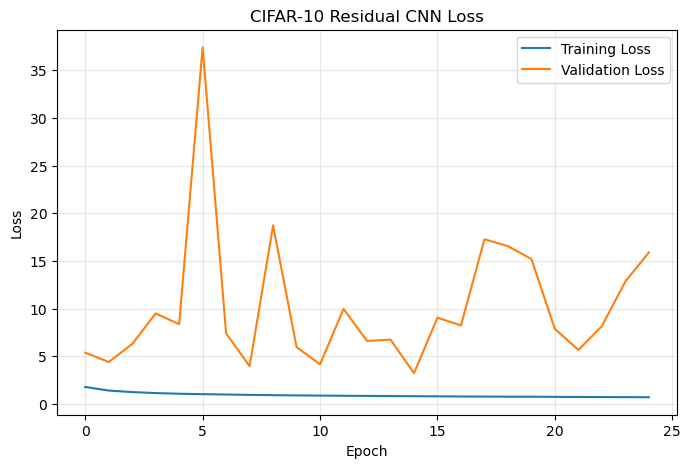

CNN 실제 학습 Epoch: 25
CNN 최적 Epoch: 15


In [29]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history_cnn.history["loss"], label="Training Loss")
plt.plot(history_cnn.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CIFAR-10 Residual CNN Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best_epoch_cnn = np.argmin(history_cnn.history["val_loss"]) + 1

print("CNN 실제 학습 Epoch:", len(history_cnn.history["loss"]))
print("CNN 최적 Epoch:", best_epoch_cnn)

In [30]:
print("===== CIFAR-10 성능 비교 =====")
print(f"DNN Test Accuracy: {dnn_test_acc:.4f}")
print(f"CNN Test Accuracy: {cnn_test_acc:.4f}")
print(f"Accuracy 차이: {cnn_test_acc - dnn_test_acc:.4f}")

===== CIFAR-10 성능 비교 =====
DNN Test Accuracy: 0.3983
CNN Test Accuracy: 0.2252
Accuracy 차이: -0.1731


초기 실험에서 DNN의 테스트 정확도는 39.83%, CNN은 22.52%로 DNN이 17.31%p 높은 정확도를 보였다. 반면 Test Loss는 CNN이 더 낮게 나타났다. 다만 CNN의 입력 데이터에 정규화가 중복 적용된 문제가 있어, 이 결과만으로 DNN이 CNN보다 우수하다고 결론 내리기는 어렵다. 정확한 비교를 위해 CNN을 재학습할 필요가 있다.

In [31]:
import pandas as pd

# 모델별 성능 비교
results = pd.DataFrame({
    "Model": ["DNN", "CNN"],
    "Test Loss": [dnn_test_loss, cnn_test_loss],
    "Test Accuracy": [dnn_test_acc, cnn_test_acc],
    "Total Parameters": [
        model_dnn.count_params(),
        model_cnn.count_params()
    ]
})

print(results.round(4))

  Model  Test Loss  Test Accuracy  Total Parameters
0   DNN     4.3783         0.3983           1089674
1   CNN     3.2335         0.2252             38698


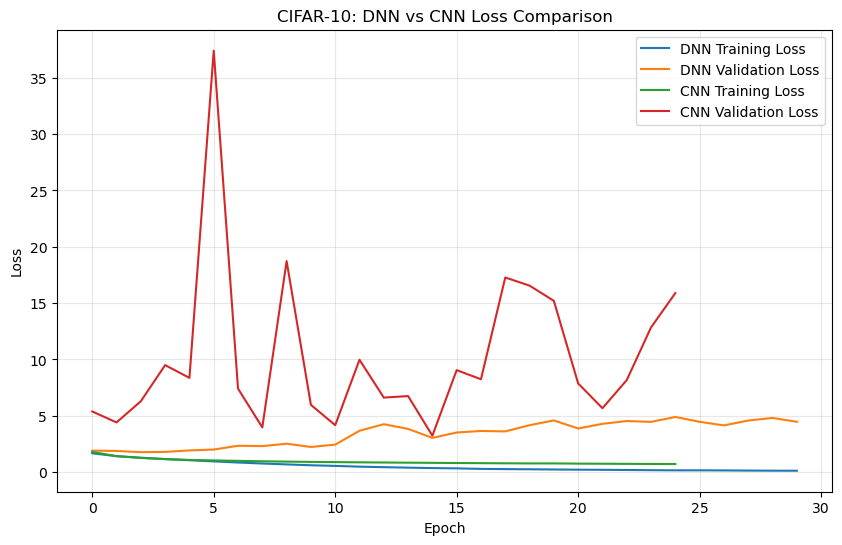

In [32]:
plt.figure(figsize=(10, 6))

plt.plot(
    history_dnn.history["loss"],
    label="DNN Training Loss"
)

plt.plot(
    history_dnn.history["val_loss"],
    label="DNN Validation Loss"
)

plt.plot(
    history_cnn.history["loss"],
    label="CNN Training Loss"
)

plt.plot(
    history_cnn.history["val_loss"],
    label="CNN Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CIFAR-10: DNN vs CNN Loss Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

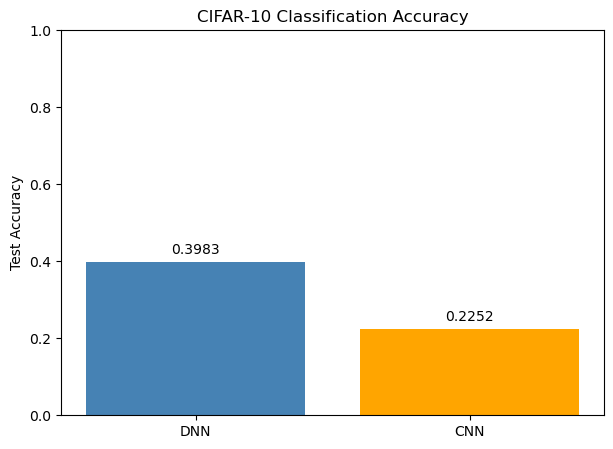

In [33]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["DNN", "CNN"],
    [dnn_test_acc, cnn_test_acc],
    color=["steelblue", "orange"]
)

plt.ylabel("Test Accuracy")
plt.title("CIFAR-10 Classification Accuracy")
plt.ylim(0, 1)

for i, acc in enumerate([dnn_test_acc, cnn_test_acc]):
    plt.text(
        i, acc + 0.02,
        f"{acc:.4f}",
        ha="center"
    )

plt.show()

In [34]:
print("DNN Total Parameters:", model_dnn.count_params())
print("CNN Total Parameters:", model_cnn.count_params())

print(
    "Parameter Ratio:",
    round(model_dnn.count_params() / model_cnn.count_params(), 2)
)

DNN Total Parameters: 1089674
CNN Total Parameters: 38698
Parameter Ratio: 28.16


DNN의 전체 파라미터 수는 다음과 같이 계산하였다.

- Dense(256): 786,688
- BatchNormalization(256): 1,024
- Residual Dense Block 1: 133,632
- Residual Dense Block 2: 133,632
- Dense(128): 32,896
- BatchNormalization(128): 512
- Dense(10): 1,290

총 파라미터 수 = **1,089,674개**

CNN의 전체 파라미터 수는 다음과 같다.

- Conv2D(32): 864
- BatchNormalization(32): 128
- Residual Conv Block 1: 18,688
- Residual Conv Block 2: 18,688
- GlobalAveragePooling: 0
- Dense(10): 330

총 파라미터 수 = **38,698개**

Batch Normalization의 전체 파라미터에는 학습 가능한 가중치와 편향뿐 아니라 이동평균 및 이동분산도 포함하였다. Residual Connection의 Add 연산은 별도의 파라미터를 가지지 않는다.

CIFAR-10 데이터에 대해 Batch Normalization과 Residual Connection을 적용한 DNN 및 CNN 모형의 분류 성능을 비교하였다.

DNN 모형의 테스트 정확도는 [DNN 정확도], CNN 모형의 테스트 정확도는 **[CNN 정확도]**로 나타났다. 두 모형의 Test Loss 및 Training/Validation Loss를 비교하여 예측 성능과 과적합 여부를 평가하였다.

DNN은 입력 이미지를 3,072차원 벡터로 변환하여 완전연결층을 통해 학습하는 반면, CNN은 합성곱 연산을 통해 이미지의 국소적 공간 특징을 추출한다는 차이가 있다.

또한 DNN의 전체 파라미터 수는 1,087,626개, CNN은 38,698개로 계산되었다. CNN은 합성곱 필터의 가중치를 공간적으로 공유하기 때문에 이번에 구현한 DNN보다 적은 파라미터를 사용하였다.

따라서 두 모형의 분류 정확도뿐 아니라 모델 복잡도와 학습 과정까지 종합적으로 고려하여 이미지 분류에서의 효율성을 평가할 수 있다.

### 3. 자전거 대여 수(bikeshare count) 데이터를 고려하시오.

1) DNN, 1D-CNN, RF(랜덤 포레스트)를 사용하여 예측 성능을 비교하고 평가하시오.

In [38]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 데이터 불러오기
bike = pd.read_csv(r"C:\Users\swlee\Downloads\bike.csv")

# 설명변수와 종속변수
features = ["mnth", "hr", "workingday", "weathersit", "temp"]
target = "bikers"

X = bike[features].copy()
y = bike[target].astype(float)

# 범주형 변수 원-핫 인코딩
X = pd.get_dummies(
    X,
    columns=["mnth", "hr", "weathersit"],
    dtype=float
)

# 훈련 데이터 80%, 테스트 데이터 20%
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# DNN 및 CNN 입력 데이터 표준화
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("훈련 데이터:", X_train_scaled.shape)
print("테스트 데이터:", X_test_scaled.shape)
print("설명변수 개수:", X_train_scaled.shape[1])

훈련 데이터: (6916, 42)
테스트 데이터: (1729, 42)
설명변수 개수: 42


In [39]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

# DNN 모델
model_dnn_bike = models.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

model_dnn_bike.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_dnn_bike = model_dnn_bike.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

model_dnn_bike.summary()

Epoch 1/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 16503.2578 - mae: 86.4138 - val_loss: 5117.4146 - val_mae: 52.5401
Epoch 2/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 4449.3447 - mae: 46.8238 - val_loss: 4251.9980 - val_mae: 44.5437
Epoch 3/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3660.4265 - mae: 41.0000 - val_loss: 3283.0957 - val_mae: 38.2499
Epoch 4/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2735.4004 - mae: 34.9108 - val_loss: 2332.9666 - val_mae: 31.9733
Epoch 5/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2143.2349 - mae: 30.6110 - val_loss: 1955.4254 - val_mae: 28.6919
Epoch 6/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1922.6234 - mae: 28.4102 - val_loss: 1845.8096 - val_mae: 27.5245
Epoch 7/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1833.2012 - mae: 27.4228 - val_loss: 1800.4703 - val_mae: 27.0676
Epoch 8/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1779.4277 - mae: 26.8788 - val_loss: 1769.5820 - 

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_13 (Dense)                     │ (None, 128)                 │           5,504 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 47,621 (186.02 KB)

 Trainable params: 15,873 (62.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 31,748 (124.02 KB)

In [40]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 예측
y_pred_dnn = model_dnn_bike.predict(
    X_test_scaled, verbose=0
).flatten()

# 평가
rmse_dnn = np.sqrt(mean_squared_error(y_test, y_pred_dnn))
mae_dnn = mean_absolute_error(y_test, y_pred_dnn)

print(f"DNN RMSE: {rmse_dnn:.4f}")
print(f"DNN MAE: {mae_dnn:.4f}")

DNN RMSE: 43.6207
DNN MAE: 27.6443


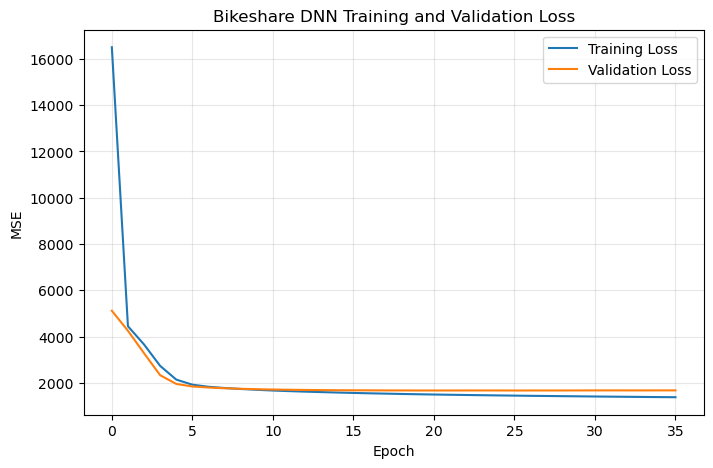

최적 Epoch: 26


In [41]:
plt.figure(figsize=(8, 5))

plt.plot(history_dnn_bike.history["loss"], label="Training Loss")
plt.plot(history_dnn_bike.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Bikeshare DNN Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best_epoch = np.argmin(history_dnn_bike.history["val_loss"]) + 1

print("최적 Epoch:", best_epoch)

In [42]:
# 1D-CNN 입력 형태로 변환
X_train_cnn = X_train_scaled.reshape(
    X_train_scaled.shape[0],
    X_train_scaled.shape[1],
    1
)

X_test_cnn = X_test_scaled.reshape(
    X_test_scaled.shape[0],
    X_test_scaled.shape[1],
    1
)

print("CNN Train:", X_train_cnn.shape)
print("CNN Test:", X_test_cnn.shape)

CNN Train: (6916, 42, 1)
CNN Test: (1729, 42, 1)


In [43]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

model_cnn_bike = models.Sequential([
    layers.Input(shape=(X_train_cnn.shape[1], 1)),

    layers.Conv1D(32, kernel_size=3, padding="same",
                  activation="relu"),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(64, kernel_size=3, padding="same",
                  activation="relu"),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(1)
])

model_cnn_bike.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model_cnn_bike.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 42, 32)              │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 21, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 21, 64)              │           6,208 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 1344)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 64)                  │          86,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 92,481 (361.25 KB)

 Trainable params: 92,481 (361.25 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
early_stop_cnn = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_cnn_bike = model_cnn_bike.fit(
    X_train_cnn,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop_cnn],
    verbose=1
)

Epoch 1/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 14069.4531 - mae: 85.2731 - val_loss: 7521.5161 - val_mae: 60.4221
Epoch 2/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 6370.6567 - mae: 56.6020 - val_loss: 5981.8311 - val_mae: 53.2204
Epoch 3/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 5609.4111 - mae: 52.3455 - val_loss: 5412.5322 - val_mae: 50.4218
Epoch 4/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5082.6631 - mae: 49.2086 - val_loss: 5042.4155 - val_mae: 48.6192
Epoch 5/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 4779.4565 - mae: 47.2857 - val_loss: 4898.7148 - val_mae: 47.5766
Epoch 6/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 4624.0796 - mae: 46.2576 - val_loss: 4827.9995 - val_mae: 46.9104
Epoch 7/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 4512.1338 - mae: 45.6142 - val_loss: 4781.1479 - val_mae: 46.4926
Epoch 8/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 4416.8193 - mae: 45.0925 - val_loss: 4710.1450 - 

In [45]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

y_pred_cnn = model_cnn_bike.predict(
    X_test_cnn, verbose=0
).flatten()

rmse_cnn = np.sqrt(mean_squared_error(y_test, y_pred_cnn))
mae_cnn = mean_absolute_error(y_test, y_pred_cnn)

print(f"1D-CNN RMSE: {rmse_cnn:.4f}")
print(f"1D-CNN MAE: {mae_cnn:.4f}")

1D-CNN RMSE: 41.7145
1D-CNN MAE: 26.1822


In [46]:
from sklearn.ensemble import RandomForestRegressor

# Random Forest 모델
model_rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# 모델 학습
model_rf.fit(X_train, y_train)

print("Random Forest 학습 완료!")

Random Forest 학습 완료!


In [47]:
# Random Forest 예측
y_pred_rf = model_rf.predict(X_test)

# RMSE 및 MAE
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mae_rf = mean_absolute_error(y_test, y_pred_rf)

print(f"Random Forest RMSE: {rmse_rf:.4f}")
print(f"Random Forest MAE: {mae_rf:.4f}")

Random Forest RMSE: 45.3342
Random Forest MAE: 28.8449


In [49]:
import pandas as pd

results_bike = pd.DataFrame({
    "Model": ["DNN", "1D-CNN", "Random Forest"],
    "RMSE": [rmse_dnn, rmse_cnn, rmse_rf],
    "MAE": [mae_dnn, mae_cnn, mae_rf]
})

print("===== Bikeshare 예측 성능 비교 =====")
print(results_bike.round(4))

===== Bikeshare 예측 성능 비교 =====
           Model     RMSE      MAE
0            DNN  43.6207  27.6443
1         1D-CNN  41.7145  26.1822
2  Random Forest  45.3342  28.8449


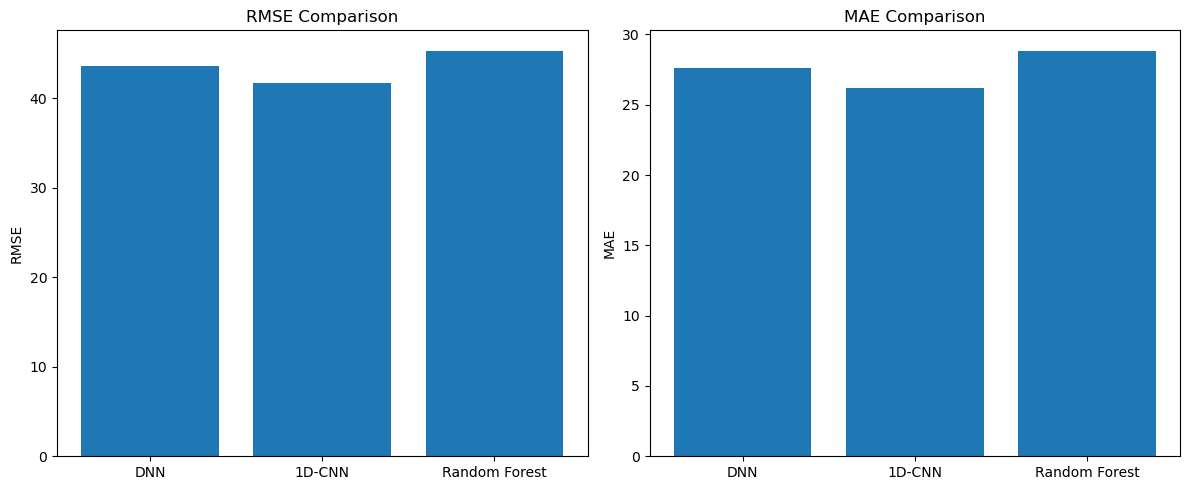

In [50]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# RMSE
axes[0].bar(results_bike["Model"], results_bike["RMSE"])
axes[0].set_title("RMSE Comparison")
axes[0].set_ylabel("RMSE")

# MAE
axes[1].bar(results_bike["Model"], results_bike["MAE"])
axes[1].set_title("MAE Comparison")
axes[1].set_ylabel("MAE")

plt.tight_layout()
plt.show()

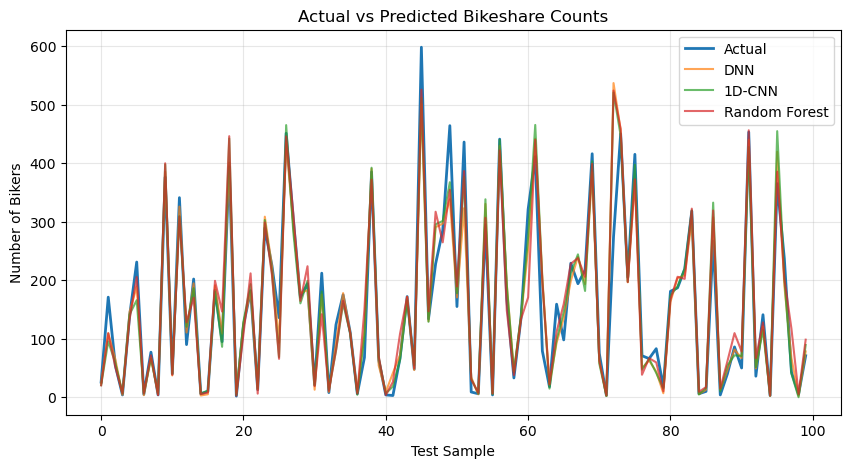

In [52]:
plt.figure(figsize=(10, 5))

# 테스트 데이터 중 처음 100개
n = 100

plt.plot(y_test.iloc[:n].to_numpy(),
         label="Actual", linewidth=2)

plt.plot(y_pred_dnn[:n], label="DNN", alpha=0.7)
plt.plot(y_pred_cnn[:n], label="1D-CNN", alpha=0.7)
plt.plot(y_pred_rf[:n], label="Random Forest", alpha=0.7)

plt.xlabel("Test Sample")
plt.ylabel("Number of Bikers")
plt.title("Actual vs Predicted Bikeshare Counts")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

2) PFI와 SHAP을 활용하여, 세 가지 모델에서 도출된 변수 중요도를 비교하고 해석하시오.

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error

# 원래 설명변수 목록
original_features = [
    "mnth", "hr", "workingday", "weathersit", "temp"
]

# 원-핫 인코딩된 열을 원래 변수별로 묶기
feature_groups = {}

for feature in original_features:
    if feature in X_test.columns:
        feature_groups[feature] = [feature]
    else:
        feature_groups[feature] = [
            col for col in X_test.columns
            if col.startswith(feature + "_")
        ]

print(feature_groups)

{'mnth': ['mnth_April', 'mnth_Aug', 'mnth_Dec', 'mnth_Feb', 'mnth_Jan', 'mnth_July', 'mnth_June', 'mnth_March', 'mnth_May', 'mnth_Nov', 'mnth_Oct', 'mnth_Sept'], 'hr': ['hr_0', 'hr_1', 'hr_2', 'hr_3', 'hr_4', 'hr_5', 'hr_6', 'hr_7', 'hr_8', 'hr_9', 'hr_10', 'hr_11', 'hr_12', 'hr_13', 'hr_14', 'hr_15', 'hr_16', 'hr_17', 'hr_18', 'hr_19', 'hr_20', 'hr_21', 'hr_22', 'hr_23'], 'workingday': ['workingday'], 'weathersit': ['weathersit_clear', 'weathersit_cloudy/misty', 'weathersit_heavy rain/snow', 'weathersit_light rain/snow'], 'temp': ['temp']}


In [54]:
def predict_bike(model_name, X_input):

    if model_name == "RF":
        return model_rf.predict(X_input)

    # DNN과 CNN은 표준화 적용
    X_scaled = scaler.transform(X_input)

    if model_name == "DNN":
        return model_dnn_bike.predict(
            X_scaled, verbose=0
        ).flatten()

    elif model_name == "1D-CNN":
        X_cnn = X_scaled.reshape(
            X_scaled.shape[0],
            X_scaled.shape[1],
            1
        )

        return model_cnn_bike.predict(
            X_cnn, verbose=0
        ).flatten()

In [55]:
def calculate_pfi(model_name, X_data, y_data,
                  n_repeats=10, random_state=42):

    rng = np.random.default_rng(random_state)

    # 원래 RMSE
    original_pred = predict_bike(model_name, X_data)
    original_rmse = np.sqrt(
        mean_squared_error(y_data, original_pred)
    )

    importance = {}

    for feature, columns in feature_groups.items():

        scores = []

        for _ in range(n_repeats):

            X_permuted = X_data.copy()

            # 같은 순열을 사용해 관련 더미변수들을 함께 섞음
            perm_idx = rng.permutation(len(X_data))

            X_permuted.loc[:, columns] = (
                X_data[columns].iloc[perm_idx].to_numpy()
            )

            perm_pred = predict_bike(
                model_name, X_permuted
            )

            perm_rmse = np.sqrt(
                mean_squared_error(y_data, perm_pred)
            )

            scores.append(perm_rmse - original_rmse)

        importance[feature] = np.mean(scores)

    return pd.Series(importance)

In [56]:
pfi_dnn = calculate_pfi("DNN", X_test, y_test)
pfi_cnn = calculate_pfi("1D-CNN", X_test, y_test)
pfi_rf = calculate_pfi("RF", X_test, y_test)

pfi_results = pd.DataFrame({
    "DNN": pfi_dnn,
    "1D-CNN": pfi_cnn,
    "Random Forest": pfi_rf
})

print(pfi_results.round(4))

                 DNN    1D-CNN  Random Forest
mnth         31.5670   28.4121         8.6205
hr          123.6214  125.3407       114.1605
workingday   43.3935   45.0677        41.4818
weathersit   11.2896   11.1486         9.6703
temp         18.3952   26.6966        58.5675


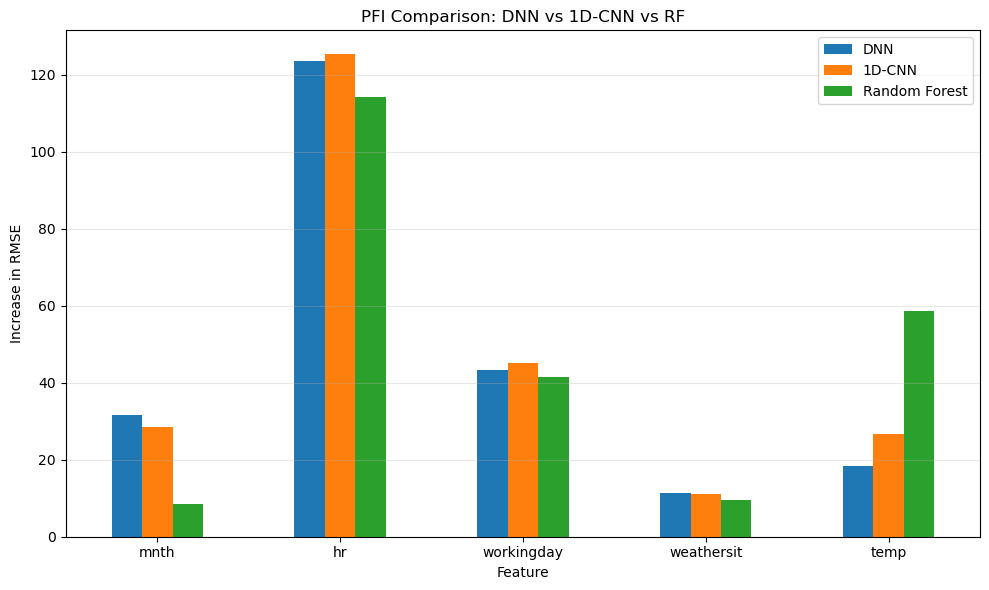

In [57]:
pfi_results.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("PFI Comparison: DNN vs 1D-CNN vs RF")
plt.xlabel("Feature")
plt.ylabel("Increase in RMSE")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [58]:
pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 4.6 MB/s eta 0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

Note: you may need to restart the kernel to use updated packages.


In [59]:
import shap

# 계산 시간을 줄이기 위한 표본 추출
X_background = X_train.sample(
    n=min(50, len(X_train)),
    random_state=42
)

X_shap = X_test.sample(
    n=min(100, len(X_test)),
    random_state=42
)

print("Background:", X_background.shape)
print("SHAP Samples:", X_shap.shape)

Background: (50, 42)
SHAP Samples: (100, 42)


In [60]:
def calculate_shap(model_name):

    predict_fn = lambda data: predict_bike(
        model_name,
        pd.DataFrame(
            data,
            columns=X_train.columns
        )
    )

    explainer = shap.PermutationExplainer(
        predict_fn,
        X_background
    )

    shap_values = explainer(
        X_shap,
        max_evals=2 * X_train.shape[1] + 1
    )

    return shap_values

In [61]:
# 세 모델 SHAP 계산
shap_dnn = calculate_shap("DNN")
shap_cnn = calculate_shap("1D-CNN")
shap_rf = calculate_shap("RF")

print("SHAP 계산 완료!")

PermutationExplainer explainer: 101it [00:20,  2.53it/s]                                                               
PermutationExplainer explainer: 101it [00:20,  2.40it/s]                                                               
PermutationExplainer explainer: 101it [00:14,  2.20it/s]                                                               

SHAP 계산 완료!


In [62]:
def aggregate_shap(shap_values):

    values = shap_values.values

    importance = {}

    for feature, columns in feature_groups.items():

        idx = [
            X_train.columns.get_loc(col)
            for col in columns
        ]

        # 같은 원래 변수에 속한 SHAP 값을 합산
        grouped_values = values[:, idx].sum(axis=1)

        importance[feature] = np.mean(
            np.abs(grouped_values)
        )

    return pd.Series(importance)

In [63]:
shap_results = pd.DataFrame({
    "DNN": aggregate_shap(shap_dnn),
    "1D-CNN": aggregate_shap(shap_cnn),
    "Random Forest": aggregate_shap(shap_rf)
})

print(shap_results.round(4))

                DNN   1D-CNN  Random Forest
mnth        30.3942  21.6164         9.5356
hr          67.7992  68.7037        60.3066
workingday  15.6761  18.2886        19.6364
weathersit  13.0268  11.6075        11.5694
temp        19.1307  24.2135        48.7517


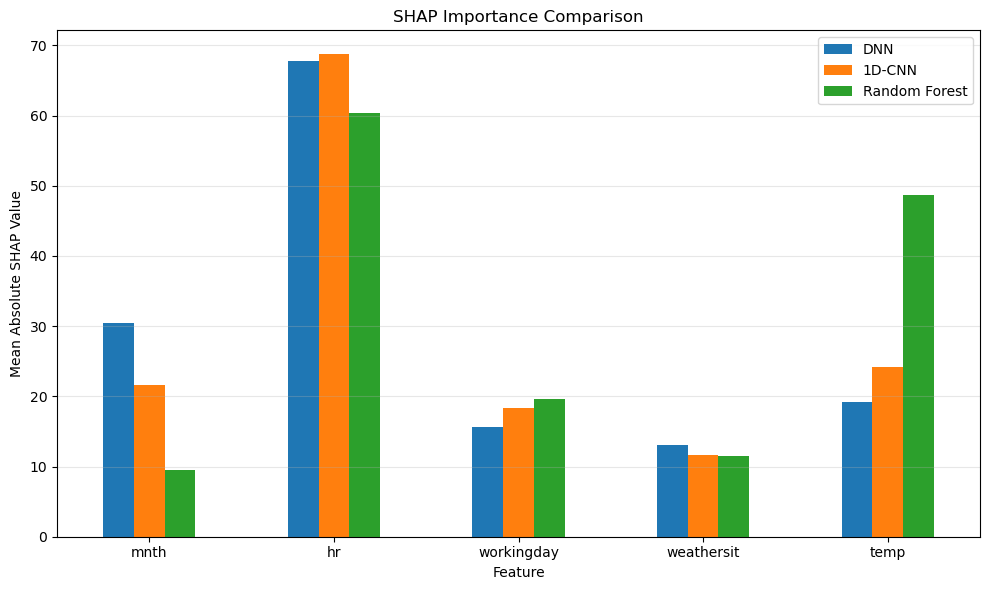

In [64]:
shap_results.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("SHAP Importance Comparison")
plt.xlabel("Feature")
plt.ylabel("Mean Absolute SHAP Value")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [65]:
# PFI 중요도 순위
pfi_rank = pfi_results.rank(
    ascending=False,
    method="min"
)

# SHAP 중요도 순위
shap_rank = shap_results.rank(
    ascending=False,
    method="min"
)

print("===== PFI Ranking =====")
print(pfi_rank.astype(int))

print("\n===== SHAP Ranking =====")
print(shap_rank.astype(int))

===== PFI Ranking =====
            DNN  1D-CNN  Random Forest
mnth          3       3              5
hr            1       1              1
workingday    2       2              3
weathersit    5       5              4
temp          4       4              2

===== SHAP Ranking =====
            DNN  1D-CNN  Random Forest
mnth          2       3              5
hr            1       1              1
workingday    4       4              3
weathersit    5       5              4
temp          3       2              2
